# Практика. Тензорное исчисление и автоматическое дифференцирование
---

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Тетрадка преподавателя выполнена целиком: код дописан во всех ячейках-заготовках, после каждого задания — выводы.
> Внешние данные не нужны. Первая ячейка кода — общие настройки запуска (устройство cuda → mps → cpu, режим быстрой
> проверки `NN_SMOKE=1`); вычисления в этой практике скалярные и выполняются на CPU.
>
> Расхождение условия и заготовки в задании 4: в тексте задания — $y = -5x + 12 + \text{шум}$, 200 точек
> на $[-10, 10]$ и RMSE, а в заготовке кода — $y = 2{,}5x + 1{,}3$ на $[0, 10]$ и MSE. Сделано по тексту
> задания (он сформулирован подробнее).

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


## Цели работы
1. Научиться создавать и преобразовывать тензоры в PyTorch.
2. Понять механизм broadcasting и выполнять базовые линейно-алгебраические операции.
3. Вычислить градиент простой функции аналитически и сравнить с результатом `autograd`.
4. Исследовать вычислительный граф на примере более сложной функции.

---

## Повторение (на пальцах 🖐️)

- **Тензор** — это просто многомерный массив. Скаляр (0D), вектор (1D), матрица (2D), кубик (3D) и дальше — сколько угодно измерений.
- **Broadcasting** — умное растягивание меньшего тензора под размер большего при выполнении операций (как когда вы на вечеринке растягиваете историю, чтобы её слушали все).
- **Градиент** — вектор частных производных. Показывает направление наискорейшего роста функции. В машинном обучении мы идём **против** градиента, чтобы уменьшить ошибку.
- **Autograd** — встроенный в PyTorch механизм автоматического дифференцирования. Он строит вычислительный граф и по команде `.backward()` раскручивает его в обратную сторону, заполняя градиенты.

Всё вспомнили? Поехали!

## Задание 1. Основы тензорных операций

**Цель:** освоиться с созданием, индексацией, broadcasting и линейной алгеброй в PyTorch.

Импортируйте PyTorch (и NumPy, если потребуется) и выполните следующие пункты. Пишите код в ячейках ниже.

1. Создайте:
   - скаляр со значением 3.14;
   - вектор из чисел от 0 до 99;
   - матрицу 3×3, заполненную единицами;
   - тензор размера 2×3×4, заполненный случайными числами из стандартного нормального распределения (используйте `torch.randn`).
2. Создайте две случайные матрицы 5×5 и сложите их поэлементно.
3. Создайте матрицу 3×4 и вектор длины 4. Выполните матричное умножение (используйте `@` или `torch.mm`). Что получилось? Какой размер у результата?
4. Создайте вектор `v = torch.tensor([1, 2, 3])` и матрицу `m = torch.tensor([[[10, 20, 30], [40, 50, 60]],[[10, 20, 30], [40, 50, 60]]])`. Сложите их (`v + m`). Объясните, как сработал broadcasting.
5. Создайте тензор формы (1, 24). Измените его форму на (3, 8) с помощью `.view()`. Что произойдёт, если вы попытаетесь изменить на (2, 13)? Проверьте и зафиксируйте ошибку.

*Подсказка:* размерности можно проверять через `.shape`.

**Выводы по заданию 1:** (напишите в Markdown-ячейке после кода)

In [2]:
# Код для задания 1
import torch

torch.manual_seed(0)

# 1. Создание тензоров
scalar = torch.tensor(3.14)
vector = torch.arange(100)                 # целые числа 0, 1, ..., 99
matrix_ones = torch.ones(3, 3)
tensor_randn = torch.randn(2, 3, 4)        # стандартное нормальное распределение
for name, t in [("scalar", scalar), ("vector", vector), ("matrix_ones", matrix_ones), ("tensor_randn", tensor_randn)]:
    print(f"{name:12s} shape={tuple(t.shape)!s:10s} ndim={t.ndim} dtype={t.dtype}")
print("первые и последние элементы вектора:", vector[:3].tolist(), "...", vector[-3:].tolist())
print("tensor_randn[1, :, 0] (индексация среза):", tensor_randn[1, :, 0])

# 2. Случайные матрицы и сложение
A = torch.randn(5, 5)
B = torch.randn(5, 5)
C = A + B
print("\nC = A + B, shape:", tuple(C.shape), "| проверка поэлементности C[2,3] == A[2,3] + B[2,3]:",
      torch.isclose(C[2, 3], A[2, 3] + B[2, 3]).item())

# 3. Матричное умножение
M = torch.randn(3, 4)
v = torch.randn(4)
result = M @ v                              # то же самое: torch.mv(M, v) или torch.matmul(M, v)
print("\nM @ v =", result, "\nразмер результата:", result.shape)
print("torch.mm требует две матрицы, поэтому вектор делаем столбцом 4x1:",
      tuple(torch.mm(M, v.unsqueeze(1)).shape))
print("совпадает с суммой M[i, j] * v[j] по j:", torch.allclose(result, (M * v).sum(dim=1)))

# 4. Broadcasting
v = torch.tensor([1, 2, 3])
m = torch.tensor([[[10, 20, 30], [40, 50, 60]], [[10, 20, 30], [40, 50, 60]]])   # тензор формы (2, 2, 3) из условия
sum_bc = v + m
print("\nv:", tuple(v.shape), " m:", tuple(m.shape), " v + m:", tuple(sum_bc.shape))
print(sum_bc)
# в заготовке m двумерная (2, 3) — broadcasting работает так же
m2 = torch.tensor([[10, 20, 30], [40, 50, 60]])
print("вариант из заготовки, m формы (2, 3):\n", v + m2)
# явное «растягивание»: то же самое, что делает broadcasting
print("v + m == v.expand_as(m) + m:", torch.equal(sum_bc, v.expand_as(m) + m))

# 5. Изменение формы
x = torch.randn(1, 24)
x_reshaped = x.view(3, 8)
print("\nx:", tuple(x.shape), "-> x.view(3, 8):", tuple(x_reshaped.shape))
print("view не копирует данные (общая память):", x_reshaped.data_ptr() == x.data_ptr())
try:
    x.view(2, 13)
except RuntimeError as e:
    print("x.view(2, 13) -> RuntimeError:", e)
print("x.view(2, -1):", tuple(x.view(2, -1).shape), "  x.view(-1, 6):", tuple(x.view(-1, 6).shape))

scalar       shape=()         ndim=0 dtype=torch.float32
vector       shape=(100,)     ndim=1 dtype=torch.int64
matrix_ones  shape=(3, 3)     ndim=2 dtype=torch.float32
tensor_randn shape=(2, 3, 4)  ndim=3 dtype=torch.float32
первые и последние элементы вектора: [0, 1, 2] ... [97, 98, 99]
tensor_randn[1, :, 0] (индексация среза): tensor([0.1665, 0.9318, 0.6181])

C = A + B, shape: (5, 5) | проверка поэлементности C[2,3] == A[2,3] + B[2,3]: True

M @ v = tensor([-0.0851, -0.3836, -0.4056]) 
размер результата: torch.Size([3])
torch.mm требует две матрицы, поэтому вектор делаем столбцом 4x1: (3, 1)
совпадает с суммой M[i, j] * v[j] по j: True

v: (3,)  m: (2, 2, 3)  v + m: (2, 2, 3)
tensor([[[11, 22, 33],
         [41, 52, 63]],

        [[11, 22, 33],
         [41, 52, 63]]])
вариант из заготовки, m формы (2, 3):
 tensor([[11, 22, 33],
        [41, 52, 63]])
v + m == v.expand_as(m) + m: True

x: (1, 24) -> x.view(3, 8): (3, 8)
view не копирует данные (общая память): True
x.view(2, 13) ->

### Выводы по заданию 1

Все пункты выполнились. Единственная ошибка — та, которую задание просит получить специально (п. 5).

- **Создание тензоров.** Скаляр имеет пустую форму `()` и 0 измерений, вектор `arange(100)` — форму `(100,)`, матрица единиц — `(3, 3)`, случайный тензор — `(2, 3, 4)`. Тип у вектора `int64`, у остальных `float32`: `arange` от целых чисел даёт целые числа, а `ones`, `randn` и `tensor(3.14)` — числа с плавающей точкой.
- **Сложение двух матриц 5×5** поэлементное: проверка `C[2,3] == A[2,3] + B[2,3]` дала `True`.
- **Матрица на вектор.** `M` (3×4) `@ v` (длина 4) даёт вектор длины 3: каждая из трёх строк `M` скалярно умножается на `v`, и размерность 4 «сокращается». Результат совпал с ручной суммой $\sum_j M_{ij} v_j$. `torch.mm` принимает только матрицы, поэтому вектор пришлось сделать столбцом 4×1, и результат получился формы `(3, 1)` — те же числа, но столбцом.
- **Broadcasting.** У `v` форма `(3,)`, у `m` — `(2, 2, 3)`. Формы сравниваются с последнего измерения: 3 и 3 совпадают, а недостающие измерения `v` считаются равными 1 и «растягиваются» до 2 и 2. В итоге `v` прибавляется к каждой строке каждой из двух матриц 2×3: дважды `[[11, 22, 33], [41, 52, 63]]`, форма `(2, 2, 3)`. Это подтвердило сравнение с явным растяжением `v.expand_as(m) + m` (`True`). С `m` формы `(2, 3)` из заготовки результат тот же, только матрица одна.
- **`view`.** Переход `(1, 24) → (3, 8)` прошёл, причём новый тензор использует ту же память (проверка `True`), то есть `view` данные не копирует. Переход в `(2, 13)` дал `RuntimeError: shape '[2, 13]' is invalid for input of size 24`: $2 \cdot 13 = 26 \ne 24$, а `view` не может ни добавить, ни выбросить элементы. Если один размер указать как `-1`, PyTorch вычислит его сам: `(2, -1) → (2, 12)`, `(-1, 6) → (4, 6)`.

## Задание 2. Ручной расчёт градиента и проверка autograd

**Цель:** убедиться, что autograd не врёт, и заодно вспомнить частные производные.

Рассмотрим функцию двух переменных (сразу смотрите функцию из бонусного варианта):
$$
f(x, y) = x^2 y + y^3
$$

1. Аналитически найдите частные производные и вычислите градиент в точке $x = 2, y = 3$. Запишите ответы (можно прямо в Markdown).
2. Создайте тензоры `x` и `y` с `requires_grad=True`, инициализировав их значениями 2 и 3.
3. Вычислите `f` и вызовите `backward()`.
4. Распечатайте `x.grad` и `y.grad`. Сравните с аналитическим расчётом.
5. **Бонус:** измените функцию, например, добавьте синус: $f = x^2 y + \sin(y)$. Повторите вычисления аналитически и через autograd.

*Подсказка:* аналитически: $\partial f/\partial x = 2xy$, $\partial f/\partial y = x^2 + 3y^2$. При (2,3): (12, 4+27=31).

**Аналитический расчёт (п. 1).** Для $f(x, y) = x^2 y + y^3$:

$$\frac{\partial f}{\partial x} = 2xy, \qquad \frac{\partial f}{\partial y} = x^2 + 3y^2,$$

в точке $(2, 3)$: $\nabla f = (2\cdot 2\cdot 3,\; 2^2 + 3\cdot 3^2) = (12,\; 31)$, а само значение $f(2,3) = 4\cdot 3 + 27 = 39$.

**Бонус (п. 5).** Для $f(x, y) = x^2 y + \sin y$:

$$\frac{\partial f}{\partial x} = 2xy = 12, \qquad \frac{\partial f}{\partial y} = x^2 + \cos y = 4 + \cos 3 \approx 4 - 0{,}98999 = 3{,}01001.$$

In [3]:
# Код для задания 2
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

f = x**2 * y + y**3
f.backward()

print("f(2, 3) =", f.item())
print("Градиент по x:", x.grad)
print("Градиент по y:", y.grad)
print("Совпадает с аналитикой (12, 31):", x.grad.item() == 12.0, y.grad.item() == 31.0)

f(2, 3) = 39.0
Градиент по x: tensor(12.)
Градиент по y: tensor(31.)
Совпадает с аналитикой (12, 31): True True


In [4]:
# Бонус: f = x^2 * y + sin(y). Новые листья графа, чтобы градиенты не накопились с прошлого вызова
import math

x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)
f = x**2 * y + torch.sin(y)
f.backward()

analytic = (2 * 2.0 * 3.0, 2.0**2 + math.cos(3.0))
print(f"autograd:  df/dx = {x.grad.item():.6f}, df/dy = {y.grad.item():.6f}")
print(f"аналитика: df/dx = {analytic[0]:.6f}, df/dy = {analytic[1]:.6f}")

# Что будет, если не обнулять градиенты: второй backward по тому же графу прибавит градиент ещё раз
f = x**2 * y + torch.sin(y)
f.backward()
print(f"после второго backward без обнуления: x.grad = {x.grad.item():.1f} (накопилось 12 + 12)")

# Независимая проверка центральной конечной разностью
def f_num(a, b):
    return a**2 * b + math.sin(b)
h = 1e-5
print(f"конечная разность: df/dy ≈ {(f_num(2, 3 + h) - f_num(2, 3 - h)) / (2 * h):.6f}")

autograd:  df/dx = 12.000000, df/dy = 3.010007
аналитика: df/dx = 12.000000, df/dy = 3.010008
после второго backward без обнуления: x.grad = 24.0 (накопилось 12 + 12)
конечная разность: df/dy ≈ 3.010008


### Выводы по заданию 2

Autograd дал $\partial f/\partial x = 12$ и $\partial f/\partial y = 31$ — ровно то, что получено вручную. Сравнение `==` вернуло `True` для обоих градиентов, значение $f(2, 3) = 39$ тоже совпало.

В бонусе с синусом совпадение до пятого знака: autograd даёт 3,010007, аналитика и конечная разность — 3,010008. Расхождение в последнем знаке — следствие одинарной точности: тензоры `float32`, а аналитическое значение посчитано через `math.cos` в двойной точности.

Как это работает. При вычислении `f` PyTorch записывает каждую операцию (степень, умножение, синус, сложение) как узел графа. `backward()` проходит граф от `f` к листьям `x` и `y` и перемножает локальные производные по правилу цепочки.

Дополнительно проверено, что градиенты **накапливаются**: второй `backward()` без обнуления дал `x.grad = 24 = 12 + 12`. Поэтому в цикле обучения градиенты обнуляются на каждом шаге — это использовано в задании 4.

## Задание 3. Исследование вычислительного графа

**Цель:** научиться отслеживать промежуточные узлы графа и понимать, откуда берутся градиенты.

Дана функция:
$$
L = (\mathbf{a} \cdot \mathbf{b} + c)^2
$$
где $\mathbf{a}, \mathbf{b}$ — векторы длины 3, $c$ — скаляр, а $\cdot$ — скалярное произведение (можно использовать `torch.dot`).

1. Задайте конкретные значения: `a = torch.tensor([1., 2., 3.], requires_grad=True)`, `b = torch.tensor([4., 5., 6.], requires_grad=True)`, `c = torch.tensor([7.], requires_grad=True)`.
2. Вычислите `L`.
3. Вызовите `backward()` и выведите градиенты по `a`, `b`, `c`.
4. Попробуйте объяснить, почему градиент по `a` именно такой. Для этого можно:
   - Вспомнить, что скалярное произведение — это сумма поэлементных произведений.
   - Записать формулу явно и взять производную по каждому компоненту.
5. (Бонус) Выведите значение промежуточного узла: `s = torch.dot(a, b) + c` и его градиент (можно получить, если сохранить его и вызвать ` s.retain_grad()  s.backward()`, но аккуратно с повторным вызовом).

**Важно:** перед повторным вызовом backward нужно обнулить градиенты, иначе они накопятся. Используйте `.zero_()`.

In [5]:
# Код для задания 3
a = torch.tensor([1., 2., 3.], requires_grad=True)
b = torch.tensor([4., 5., 6.], requires_grad=True)
c = torch.tensor([7.], requires_grad=True)

s = torch.dot(a, b) + c
L = s ** 2
L.backward()

print("s =", s.item(), "  L =", L.item())
print("grad a:", a.grad)
print("grad b:", b.grad)
print("grad c:", c.grad)
print("ожидание по формулам: 2s·b =", (2 * s * b).detach(), " 2s·a =", (2 * s * a).detach(), " 2s =", (2 * s).item())
print("узлы графа:", L.grad_fn, "<-", L.grad_fn.next_functions[0][0], "<-",
      L.grad_fn.next_functions[0][0].next_functions[0][0])

# Бонус: градиент по промежуточному узлу s (обнуляем накопленные градиенты листьев)
a.grad.zero_(); b.grad.zero_(); c.grad.zero_()
s = torch.dot(a, b) + c
s.retain_grad()            # s — не лист графа, без retain_grad его градиент не сохраняется
L = s ** 2
L.backward()
print("\nградиент по s (dL/ds = 2s):", s.grad)
print("grad a (через s): dL/ds * ds/da = 2s * b =", a.grad)

s = 39.0   L = 1521.0
grad a: tensor([312., 390., 468.])
grad b: tensor([ 78., 156., 234.])
grad c: tensor([78.])
ожидание по формулам: 2s·b = tensor([312., 390., 468.])  2s·a = tensor([ 78., 156., 234.])  2s = 78.0
узлы графа: <PowBackward0 object at 0x111fbd990> <- <AddBackward0 object at 0x11284bd90> <- <DotBackward0 object at 0x1121597e0>

градиент по s (dL/ds = 2s): tensor([78.])
grad a (через s): dL/ds * ds/da = 2s * b = tensor([312., 390., 468.])


### Выводы по заданию 3

Получилось $s = \mathbf a \cdot \mathbf b + c = 4 + 10 + 18 + 7 = 39$ и $L = 39^2 = 1521$. Градиенты:
- по $\mathbf a$: (312, 390, 468);
- по $\mathbf b$: (78, 156, 234);
- по $c$: 78.

**Почему градиент по $\mathbf a$ именно такой.** $L = s^2$, где $s = a_1 b_1 + a_2 b_2 + a_3 b_3 + c$. По правилу цепочки $\partial L/\partial a_i = \partial L/\partial s \cdot \partial s/\partial a_i = 2s \cdot b_i$. Множитель $2s = 78$ общий для всех компонент, а дальше каждая компонента $\mathbf a$ умножается на соответствующую компоненту $\mathbf b$: $78 \cdot (4, 5, 6) = (312, 390, 468)$. Симметрично градиент по $\mathbf b$ равен $2s \cdot \mathbf a = 78 \cdot (1, 2, 3)$, а по $c$ — просто $2s$, потому что $\partial s/\partial c = 1$. Все три результата совпали с формулами в выводе ячейки.

Структура функции видна и в самом графе: `PowBackward0 ← AddBackward0 ← DotBackward0`, то есть квадрат, сложение с $c$ и скалярное произведение в обратном порядке. Именно в таком порядке их проходит градиент.

**Бонус.** После `s.retain_grad()` у промежуточного узла появляется свой градиент $\partial L/\partial s = 78 = 2s$. Если умножить его на $\partial s/\partial \mathbf a = \mathbf b$, получается тот же градиент по $\mathbf a$. Значит, autograd действительно считает по цепочке через промежуточный узел. Без `retain_grad()` градиенты промежуточных узлов не сохраняются, остаются только градиенты листьев.

## Задание 4. Линейная регрессия с autograd

**Цель:** применить autograd для обучения простой модели.

Сгенерируйте данные:
$$y_{\text{true}} = -5 x + 12 + \text{шум}$$
для 200 точек x от -10 до 10.

Инициализируйте случайные параметры `w` и `b` с `requires_grad=True`. Напишите цикл обучения на 100 эпох:
- оценка целевой функции `y_pred = w * x + b`;
- функция потерь: RMSE (`((y_pred - y_true)**2).mean()`) (добавить корень);
- `loss.backward()`;
- обновление весов вручную (без оптимизатора): `w.data -= lr * w.grad`, `b.data -= lr * b.grad` (используйте `.data` или блок `torch.no_grad()`);
- обнуление градиентов.

Выведите итоговые параметры и постройте
1. График изменения loss с увеличением эпох;
2. Линейные графики исходной и полученной функций;
3. График самой функции loss и движение поиска минимума по ней.

*Подсказка:* не забудьте обнулять градиенты после каждого шага.

Это задание повторяет пример из лекции — попробуйте выполнить его без подглядывания, а потом сверьтесь.

Начальные значения: w = -1.284, b = -0.692
Результат: w = -5.025, b = 11.973, RMSE = 2.942
МНК (точное решение): w = -5.025, b = 12.138, RMSE = 2.936


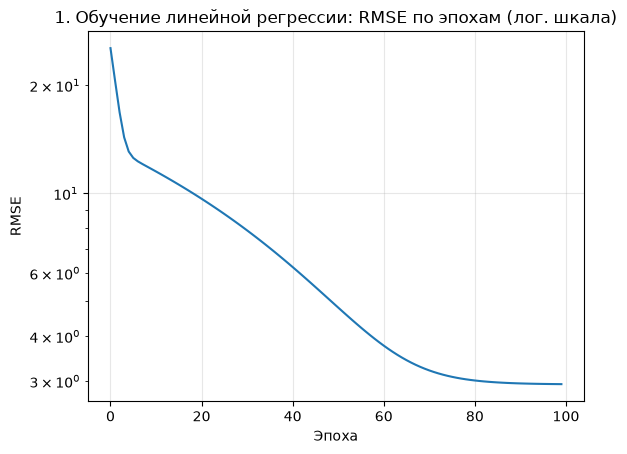

In [6]:
# Код для задания 4
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Генерация данных по условию: y = -5x + 12 + шум, 200 точек на [-10, 10]
x_true = torch.linspace(-10, 10, 200)
y_true = -5 * x_true + 12 + torch.randn_like(x_true) * 3.0

# Инициализация параметров
w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
w_init, b_init = w.item(), b.item()

lr = 0.2      # подобран ниже по сравнению нескольких значений (см. выводы)
loss_history, path = [], [(w.item(), b.item())]

for epoch in range(100):
    # Прямой проход
    y_pred = w * x_true + b
    loss = torch.sqrt(((y_pred - y_true) ** 2).mean())      # RMSE
    loss_history.append(loss.item())

    # Обратный проход
    loss.backward()

    # Обновление весов
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    # Обнуление градиентов
    w.grad.zero_()
    b.grad.zero_()
    path.append((w.item(), b.item()))

print(f"Начальные значения: w = {w_init:.3f}, b = {b_init:.3f}")
print(f"Результат: w = {w.item():.3f}, b = {b.item():.3f}, RMSE = {loss_history[-1]:.3f}")

# Сверка с точным решением МНК (нормальные уравнения)
X = torch.stack([x_true, torch.ones_like(x_true)], dim=1)
w_ls, b_ls = torch.linalg.lstsq(X, y_true.unsqueeze(1)).solution.squeeze().tolist()
rmse_ls = torch.sqrt(((X @ torch.tensor([w_ls, b_ls]) - y_true) ** 2).mean()).item()
print(f"МНК (точное решение): w = {w_ls:.3f}, b = {b_ls:.3f}, RMSE = {rmse_ls:.3f}")

plt.plot(loss_history)
plt.xlabel("Эпоха")
plt.ylabel("RMSE")
plt.yscale("log")
plt.title("1. Обучение линейной регрессии: RMSE по эпохам (лог. шкала)")
plt.grid(True, alpha=0.3)
plt.show()

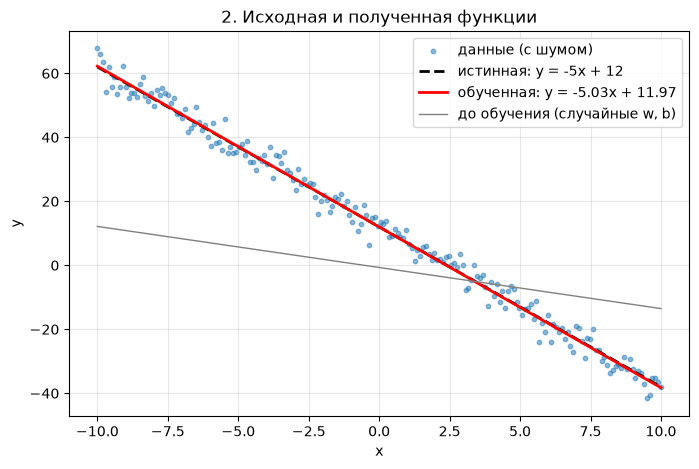

In [7]:
# 2. Исходная (истинная) зависимость, данные и полученная прямая
plt.figure(figsize=(8, 5))
plt.scatter(x_true, y_true, s=10, alpha=0.5, label="данные (с шумом)")
plt.plot(x_true, -5 * x_true + 12, "k--", lw=2, label="истинная: y = -5x + 12")
with torch.no_grad():
    plt.plot(x_true, w * x_true + b, "r", lw=2, label=f"обученная: y = {w.item():.2f}x + {b.item():.2f}")
    plt.plot(x_true, w_init * x_true + b_init, color="gray", lw=1, label="до обучения (случайные w, b)")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(True, alpha=0.3)
plt.title("2. Исходная и полученная функции")
plt.show()

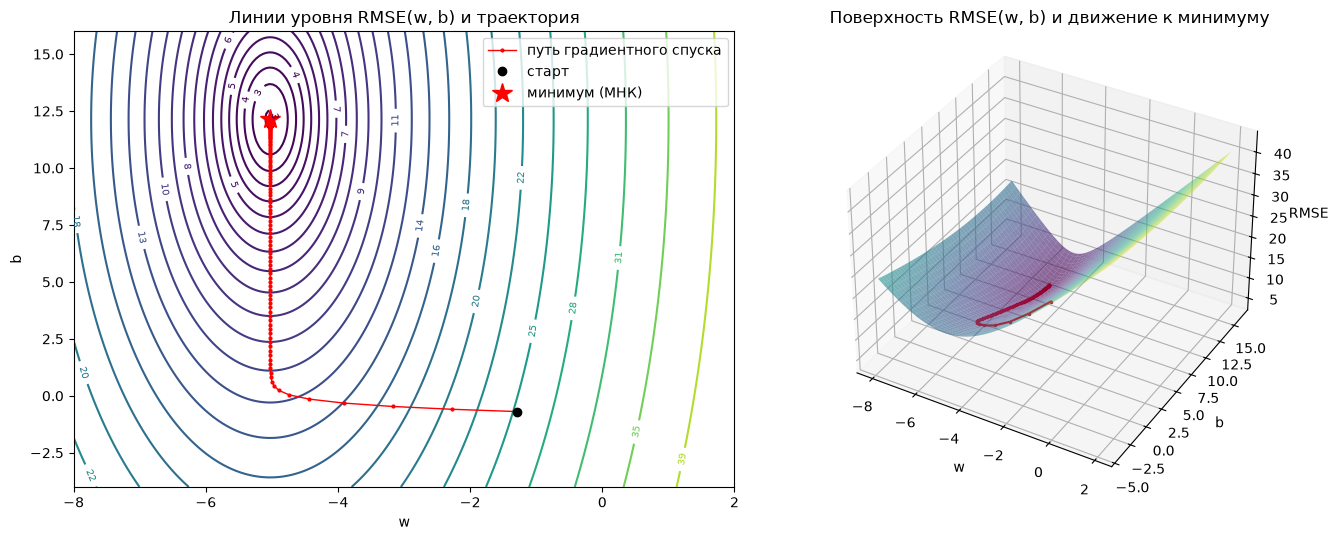

In [8]:
# 3. Поверхность функции потерь RMSE(w, b) и путь градиентного спуска по ней
import numpy as np

ws = np.linspace(-8, 2, 200)
bs = np.linspace(-4, 16, 200)
Wg, Bg = np.meshgrid(ws, bs)
xn, yn = x_true.numpy(), y_true.numpy()
# RMSE для каждой пары (w, b) сразу на всей сетке: broadcasting (200, 200, 1) против (200,)
R = np.sqrt((((Wg[..., None] * xn + Bg[..., None]) - yn) ** 2).mean(axis=-1))
P = np.array(path)

fig = plt.figure(figsize=(14, 5.5))
ax = fig.add_subplot(1, 2, 1)
cs = ax.contour(Wg, Bg, R, levels=np.geomspace(R.min() * 1.01, R.max(), 25), cmap="viridis")
ax.clabel(cs, fontsize=7, fmt="%.0f")
ax.plot(P[:, 0], P[:, 1], "r.-", ms=4, lw=1, label="путь градиентного спуска")
ax.plot(P[0, 0], P[0, 1], "ko", label="старт")
ax.plot(w_ls, b_ls, "r*", ms=15, label="минимум (МНК)")
ax.set_xlabel("w"); ax.set_ylabel("b"); ax.legend(); ax.set_title("Линии уровня RMSE(w, b) и траектория")

ax3 = fig.add_subplot(1, 2, 2, projection="3d")
ax3.plot_surface(Wg, Bg, R, cmap="viridis", alpha=0.6, linewidth=0)
loss_path = np.sqrt((((P[:, :1] * xn + P[:, 1:]) - yn) ** 2).mean(axis=1))
ax3.plot(P[:, 0], P[:, 1], loss_path, "r.-", ms=3, lw=1.5)
ax3.set_xlabel("w"); ax3.set_ylabel("b"); ax3.set_zlabel("RMSE")
ax3.set_title("Поверхность RMSE(w, b) и движение к минимуму")
ax3.view_init(elev=35, azim=-60)
plt.tight_layout()
plt.show()

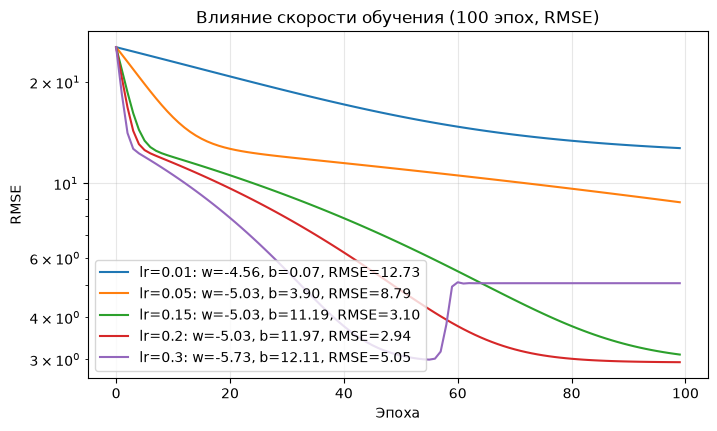

lr=0.15, 100 эпох: w = -5.025, b = 11.193, RMSE = 3.100
lr=0.15, 200 эпох: w = -5.025, b = 12.133, RMSE = 2.936
lr=0.15, 300 эпох: w = -5.025, b = 12.138, RMSE = 2.936
lr=0.2, 100 эпох: w = -5.025, b = 11.973, RMSE = 2.942
lr=0.2, 200 эпох: w = -5.025, b = 12.138, RMSE = 2.936
lr=0.2, 300 эпох: w = -5.025, b = 12.138, RMSE = 2.936


In [9]:
# Почему lr = 0.2: сравнение нескольких скоростей обучения на тех же данных и старте
def fit_rmse(lr, epochs=100):
    w = torch.tensor([w_init], requires_grad=True)
    b = torch.tensor([b_init], requires_grad=True)
    hist = []
    for _ in range(epochs):
        loss = torch.sqrt(((w * x_true + b - y_true) ** 2).mean())
        hist.append(loss.item())
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad; b -= lr * b.grad
        w.grad.zero_(); b.grad.zero_()
    return hist, w.item(), b.item()

plt.figure(figsize=(8, 4.5))
for lr_try in [0.01, 0.05, 0.15, 0.2, 0.3]:
    h, w_t, b_t = fit_rmse(lr_try)
    plt.plot(h, label=f"lr={lr_try}: w={w_t:.2f}, b={b_t:.2f}, RMSE={h[-1]:.2f}")
plt.yscale("log"); plt.xlabel("Эпоха"); plt.ylabel("RMSE"); plt.grid(True, alpha=0.3)
plt.legend(); plt.title("Влияние скорости обучения (100 эпох, RMSE)")
plt.show()

# Хватит ли 100 эпох? Продлим обучение для lr = 0.15 и lr = 0.2
for lr_try in [0.15, 0.2]:
    for ep in [100, 200, 300]:
        h, w_t, b_t = fit_rmse(lr_try, epochs=ep)
        print(f"lr={lr_try}, {ep} эпох: w = {w_t:.3f}, b = {b_t:.3f}, RMSE = {h[-1]:.3f}")

### Выводы по заданию 4

**Обучить удалось.** Случайный старт: $w = -1{,}284$, $b = -0{,}692$. За 100 эпох при `lr = 0.2` получено $w = -5{,}025$, $b = 11{,}973$, RMSE = 2,942. Точное решение МНК на тех же данных: $w = -5{,}025$, $b = 12{,}138$, RMSE = 2,936. То есть градиентный спуск почти дошёл до минимума.

От «истинных» −5 и 12 решение отличается из-за шума. RMSE ≈ 2,94 близка к его стандартному отклонению 3: меньшую ошибку прямая на этих данных дать не может.

**Главная сложность видна на линиях уровня.** Они вытянуты в сильно сплюснутые эллипсы. По $w$ функция крутая, потому что производная по $w$ умножается на $x$, а $|x|$ доходит до 10. По $b$ функция пологая. Поэтому за первые несколько шагов $w$ почти сразу встаёт на −5, а потом точка долго ползёт по «долине» вдоль $b$. Скорость обучения одна на оба параметра, и её ограничивает крутое направление.

Сравнение скоростей обучения (100 эпох, один и тот же старт):

| lr | $w$ | $b$ | RMSE |
|---|---|---|---|
| 0,01 | −4,56 | 0,07 | 12,73 |
| 0,05 | −5,03 | 3,90 | 8,79 |
| 0,15 | −5,03 | 11,19 | 3,10 |
| 0,2 | −5,03 | 11,97 | 2,94 |
| 0,3 | −5,73 | 12,11 | 5,05 |

- При маленьком шаге $b$ не успевает дойти до 12.
- При `lr = 0.3` RMSE сначала падает быстрее всех, но около 60-й эпохи скачком вырастает до 5,05 и дальше не меняется. При этом $w = -5{,}73$ вместо −5,03. Судя по этому, шаг слишком велик для крутого направления: $w$ перескакивает минимум то в одну, то в другую сторону с постоянным размахом.
- Выбран `lr = 0.2`: только с ним за 100 эпох RMSE почти равна минимальной (2,942 против 2,936). С `lr = 0.15` за 100 эпох RMSE ещё 3,10. За 200 эпох оба варианта доходят до решения МНК.

Ещё одна трудность — расхождение условия и заготовки (описано в начале тетрадки). Сделано по тексту задания.

## Заключение

Поздравляю, вы пережили первое практическое занятие! Теперь вы умеете:
- создавать тензоры любой размерности;
- использовать broadcasting;
- считать градиенты вручную и доверять autograd;
- строить простые вычислительные графы.

Эти навыки пригодятся уже на следующем занятии, когда мы будем визуализировать градиентный спуск. Если остались вопросы — не стесняйтесь задавать (и да, чат с одногруппниками тоже работает).

**Сдавайте выполненную работу в виде этого блокнота с заполненными ячейками и выводами.**

Успехов!